## Import 

In [1]:
from __future__ import annotations
import pandas as pd
import numpy as np
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import warnings
warnings.filterwarnings("ignore")
import hdf5plugin #in case needed for h5ad reading (if previously saved with compression)
import decoupler as dc
import os
import seaborn as sns
from scipy.stats import median_abs_deviation
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


## Read data

In [ ]:
tumor_data = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/snrna_data.h5ad")

In [ ]:
tumor_data.layers["counts"] = tumor_data.X
tumor_data.raw = tumor_data.copy()

In [ ]:
tumor_data.obs["mutation"] = tumor_data.obs["orig.ident"].map({
  "GSM8058157_KK22-H-225": "C19MC",
  "GSM8058158_KK22-H-226": "C19MC",
  "GSM8058159_KK22-H-227": "Dicer",
  "GSM8058160_KK23-H-507": "C19MC",
  "GSM8058161_KK23-H-508": "C19MC",
  "GSM8058162_KK23-H-509": "C19MC",
  "GSM8058163_KK23-H-510": "C19MC",
  "GSM8058164_KK23-H-511": "C19MC",
  "GSM8058165_KK23-H-512": "C19MC"
})


In [ ]:
# I'm working with each tumor separately so I can see which ones integrate better with the humanized data

tumor1, tumor2, tumor3, tumor4, tumor5, tumor6, tumor7, tumor8, tumor9 = [x for _, x in tumor_data.obs.groupby(tumor_data.obs['orig.ident'])]

tumor1

,orig.ident,mutation
AAACAAGCATTCGGTTACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
AAACCAGGTTGCATCGACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
AAACGGGCAATAACCGACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
AAACTGGGTGCACAAAACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
AAAGATGCAATCGTGAACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
...,...,...
TTTGGACGTATGGTCTACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
TTTGGACGTCCAATACACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
TTTGGCGGTATGTTGCACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC
TTTGTGAGTCATTATGACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC


In [20]:
tumor_data[tumor1.index]

View of AnnData object with n_obs × n_vars = 2107 × 18082
    obs: 'orig.ident', 'mutation'
    var: 'gene_ids', 'feature_types'
    layers: 'counts'

## Filtering and transforming data

In [21]:
#This is snRNA data, so there shouldn´t be any mitochondrial contamination, but I will filter the data just in case. I would also filter out ribosomal genes, but I can't find any

def filter_adata(adata):
    adata = tumor_data[adata.index].copy()
    # mitochondrial genes
    adata.var["mt"] = adata.var_names.str.startswith("MT-")
    adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', "ribo"], percent_top=None, log1p=False, inplace=True)
    adata = adata[
    adata.obs['n_genes_by_counts'].between(200, 6000) &
    (adata.obs['total_counts'] < 40000) &
    (adata.obs['pct_counts_mt'] < 5) ,
    :
    ].copy()# ribosomal genes
    return adata




In [29]:
def preprocess_adata(adata):
    sc.pp.highly_variable_genes(adata, flavor='seurat_v3', layer="counts") #identify highly variable genes, IMPORTANT TO DO BEFORE NORMALIZATION AND LOG-TRANSFORMATION
    sc.pp.normalize_total(adata, target_sum=1e4) #library size normalization
    sc.pp.log1p(adata) #log-transformation
    adata.raw = adata.copy() #store the unnormalized data in the .raw attribute
    adata.layers["scale.data"] = adata.X.copy() #store the unnormalized data in a new layer called "scale.data"
    sc.pp.scale(adata, layer="scale.data")
    adata.write_h5ad(f"/home/sofia/Projects/etmr/defaria/snRNA/data/processed/{adata.obs['orig.ident'][0]}_preprocessed.h5ad")
    return adata


In [30]:
tumor1_data = filter_adata(tumor1)
tumor1_data = preprocess_adata(tumor1_data)

... storing 'mutation' as categorical


| Concept         | Seurat Column     | AnnData Column (Scanpy default) |
| --------------- | ----------------- | ------------------------------- |
| Cluster ID      | `seurat_clusters` | `leiden` or `louvain`           |
| Sample          | `orig.ident`      | `sample` (user-defined)         |
| UMI count       | `nCount_RNA`      | `total_counts`                  |
| Genes detected  | `nFeature_RNA`    | `n_genes_by_counts`             |
| % mitochondrial | `percent.mt`      | `pct_counts_mt`                 |
| Condition       | `condition`       | `condition`                     |


## Checkpoint

In [3]:
tumor1_data = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/GSM8058157_KK22-H-225_preprocessed.h5ad")
tumor1_data

AnnData object with n_obs × n_vars = 2069 × 18082
    obs: 'orig.ident', 'mutation', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

In [4]:
humanized_data = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/mouse/so_12_SP_WT_KO_joined_humanized.h5ad")

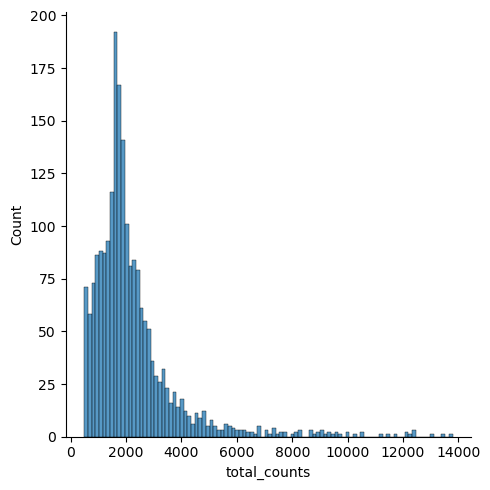

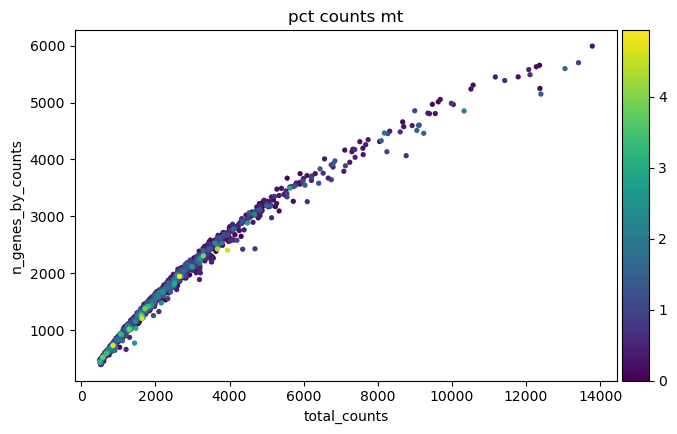

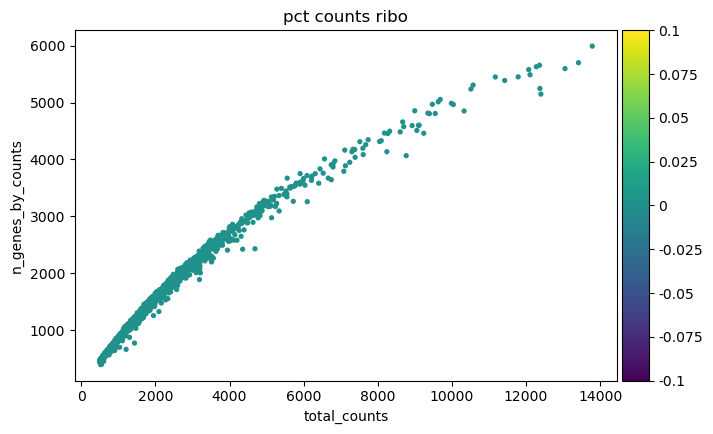

In [5]:
p1 = sns.displot(tumor1_data.obs["total_counts"], bins=100, kde=False)
p2 = sc.pl.scatter(tumor1_data, "total_counts", "n_genes_by_counts", color="pct_counts_mt")
p3 = sc.pl.scatter(tumor1_data, "total_counts", "n_genes_by_counts", color="pct_counts_ribo")

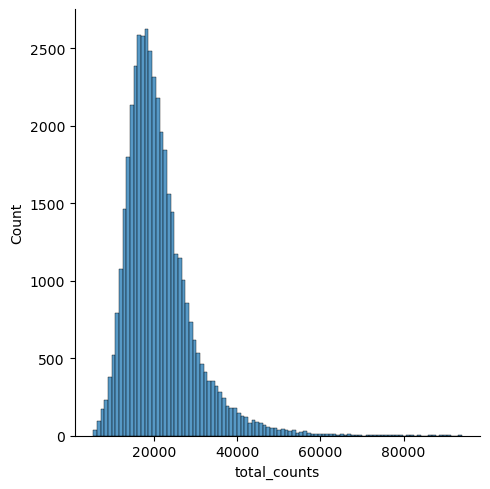

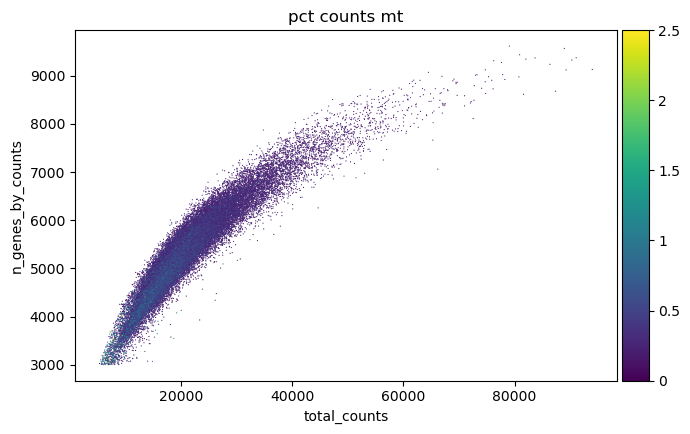

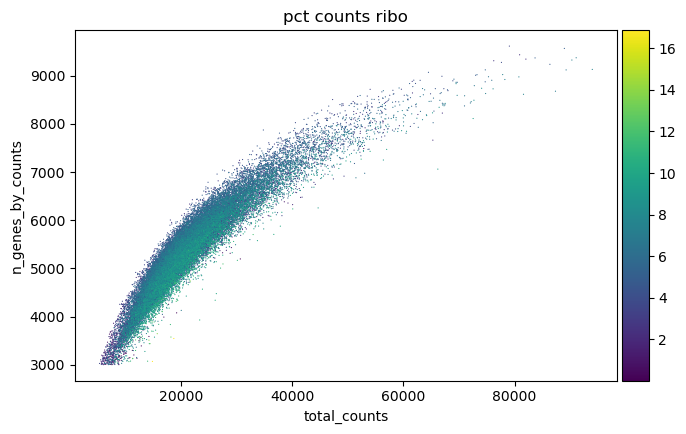

In [6]:
p1 = sns.displot(humanized_data.obs["total_counts"], bins=100, kde=False)
p2 = sc.pl.scatter(humanized_data, "total_counts", "n_genes_by_counts", color="pct_counts_mt")
p3 = sc.pl.scatter(humanized_data, "total_counts", "n_genes_by_counts", color="pct_counts_ribo")

In [7]:
# Check the distribution of ribosomal genes
#There's nothing, probably because this is snRNA-seq data and ribosomal genes are mostly cytoplasmic

tumor1_data.var.loc[tumor1_data.var["ribo"]]

,gene_ids,feature_types,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std


In [8]:
humanized_data.var.loc[humanized_data.var["ribo"]]

,names,mt,ribo,n_cells_by_counts-KO,mean_counts-KO,pct_dropout_by_counts-KO,total_counts-KO,highly_variable-KO,highly_variable_rank-KO,means-KO,...,variances_norm-WT,mean-WT,std-WT,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std
RPS6KC1,Rps6kc1,False,True,7829,0.356570,73.723779,10624.0,False,NaN,0.443297,...,0.888262,0.143473,0.242291,False,NaN,0.431316,0.571234,0.840995,0.150084,0.246257
RPS21,Rps21,False,True,27337,20.775936,8.249706,619019.0,False,NaN,26.380688,...,0.941870,2.615267,0.569187,False,NaN,28.891253,476.802527,1.141123,2.488378,0.636771
RPS3A,Rps3a1,False,True,27595,31.659305,7.383789,943289.0,False,NaN,40.409170,...,0.715474,2.956107,0.509297,False,NaN,41.936810,603.137862,0.706098,2.926546,0.486513
RPS20,Rps20,False,True,27759,29.913710,6.833361,891279.0,False,NaN,38.003631,...,0.843994,2.947374,0.608272,False,NaN,41.336090,725.688384,0.873769,2.864565,0.598140
RPS6,Rps6,False,True,21142,3.739990,29.041786,111433.0,False,NaN,4.774895,...,1.331792,1.262111,0.609320,False,NaN,5.873110,38.161716,1.534788,1.092300,0.637702
RPS8,Rps8,False,True,28230,43.807753,5.252559,1305252.0,False,NaN,55.605355,...,0.766429,3.328817,0.547910,False,NaN,60.109699,1459.509107,0.838889,3.238928,0.560427
RPS6KA1,Rps6ka1,False,True,2465,0.094244,91.726800,2808.0,False,NaN,0.117868,...,0.885178,0.048225,0.141591,False,NaN,0.125380,0.153200,0.839478,0.045236,0.137989
RPS9,Rps9,False,True,27741,31.470079,6.893774,937651.0,False,NaN,40.058190,...,0.641094,3.002036,0.469645,False,NaN,42.347102,580.244609,0.666531,2.944431,0.473021
RPS5,Rps5,False,True,27563,27.154321,7.491190,809063.0,False,NaN,34.553553,...,0.699649,2.779696,0.515363,False,NaN,35.305285,423.810363,0.692201,2.764420,0.504134
RPS19,Rps19,False,True,27281,18.893271,8.437657,562925.0,False,NaN,23.881607,...,0.906407,2.420145,0.589776,False,NaN,24.843722,299.174327,0.950754,2.382024,0.581111


In [9]:
tumor1_data.layers["scale.data"][5:10, 5:10]

array([[ 0.08379637, -0.2399785 ,  0.42180758,  0.        , -0.27592121],
       [ 0.03378297, -0.2399785 ,  1.55170543,  0.        , -0.27592121],
       [-1.42732195, -0.2399785 ,  0.03781893,  0.        , -0.27592121],
       [ 0.54897993, -0.2399785 , -1.25763719,  0.        , -0.27592121],
       [ 1.52379497, -0.2399785 ,  0.27281555,  0.        , -0.27592121]])

In [10]:
tumor1_data.layers["counts"].toarray()[5:10, 5:10]

array([[1., 0., 1., 0., 0.],
       [2., 0., 9., 0., 0.],
       [0., 0., 1., 0., 0.],
       [2., 0., 0., 0., 0.],
       [9., 0., 1., 0., 0.]], dtype=float32)

In [11]:
tumor1_data.X.toarray()[5:10, 5:10]

array([[1.9534912, 0.       , 1.9534912, 0.       , 0.       ],
       [1.8888366, 0.       , 3.2677622, 0.       , 0.       ],
       [0.       , 0.       , 1.5068445, 0.       , 0.       ],
       [2.554855 , 0.       , 0.       , 0.       , 0.       ],
       [3.8150427, 0.       , 1.7801871, 0.       , 0.       ]],
      dtype=float32)

In [12]:
tumor1_data.var.loc[tumor1_data.var["highly_variable"]]

,gene_ids,feature_types,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std
TTLL10,ENSG00000162571,Gene Expression,False,False,8,0.006645,99.620313,14.0,True,676.0,0.005800,0.016407,1.621027,0.007217,0.127802
TNFRSF4,ENSG00000186827,Gene Expression,False,False,4,0.002373,99.810157,5.0,True,1568.0,0.002417,0.003379,1.250054,0.003806,0.089319
VWA1,ENSG00000179403,Gene Expression,False,False,173,0.115330,91.789274,243.0,True,393.0,0.107782,0.262555,1.993300,0.135496,0.487154
GABRD,ENSG00000187730,Gene Expression,False,False,54,0.043664,97.437114,92.0,True,271.0,0.041566,0.117227,2.268260,0.047135,0.315175
PRKCZ,ENSG00000067606,Gene Expression,False,False,108,0.069293,94.874229,146.0,True,1244.0,0.067666,0.108572,1.336243,0.095929,0.435698
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-ND4L,ENSG00000212907,Gene Expression,True,False,976,1.193166,53.678215,2514.0,True,507.0,1.057999,4.274197,1.807173,0.986490,1.157206
MT-ND4,ENSG00000198886,Gene Expression,True,False,808,0.907451,61.651637,1912.0,True,513.0,0.814886,2.855949,1.796598,0.796972,1.095644
MT-ND5,ENSG00000198786,Gene Expression,True,False,354,0.266730,83.198861,562.0,True,958.0,0.231029,0.435961,1.442545,0.292409,0.712122
MT-ND6,ENSG00000198695,Gene Expression,True,False,1363,2.820123,35.310869,5942.0,True,456.0,2.565007,19.909336,1.870364,1.663675,1.393595


## Dimensionality reduction

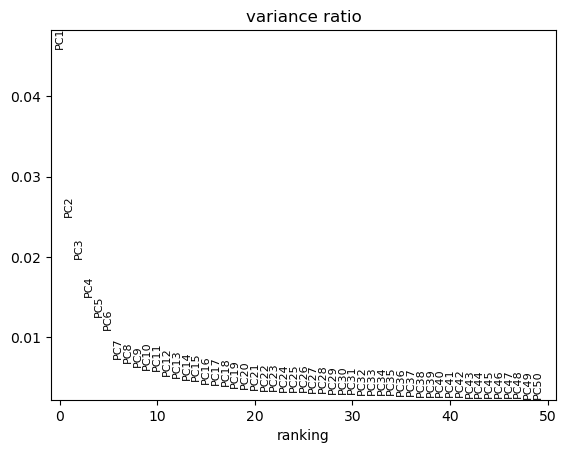

In [17]:
sc.pp.pca(tumor1_data, use_highly_variable=True,  n_comps=50, layer="scale.data")
sc.pl.pca_variance_ratio(tumor1_data, n_pcs=50, log=False)
sc.pp.neighbors(
                tumor1_data,
                n_neighbors=20,
                n_pcs=30
            )

            # UMAP
sc.tl.umap(
                tumor1_data
            )

            # Leiden
sc.tl.leiden(
                tumor1_data,
                resolution=.8
            )

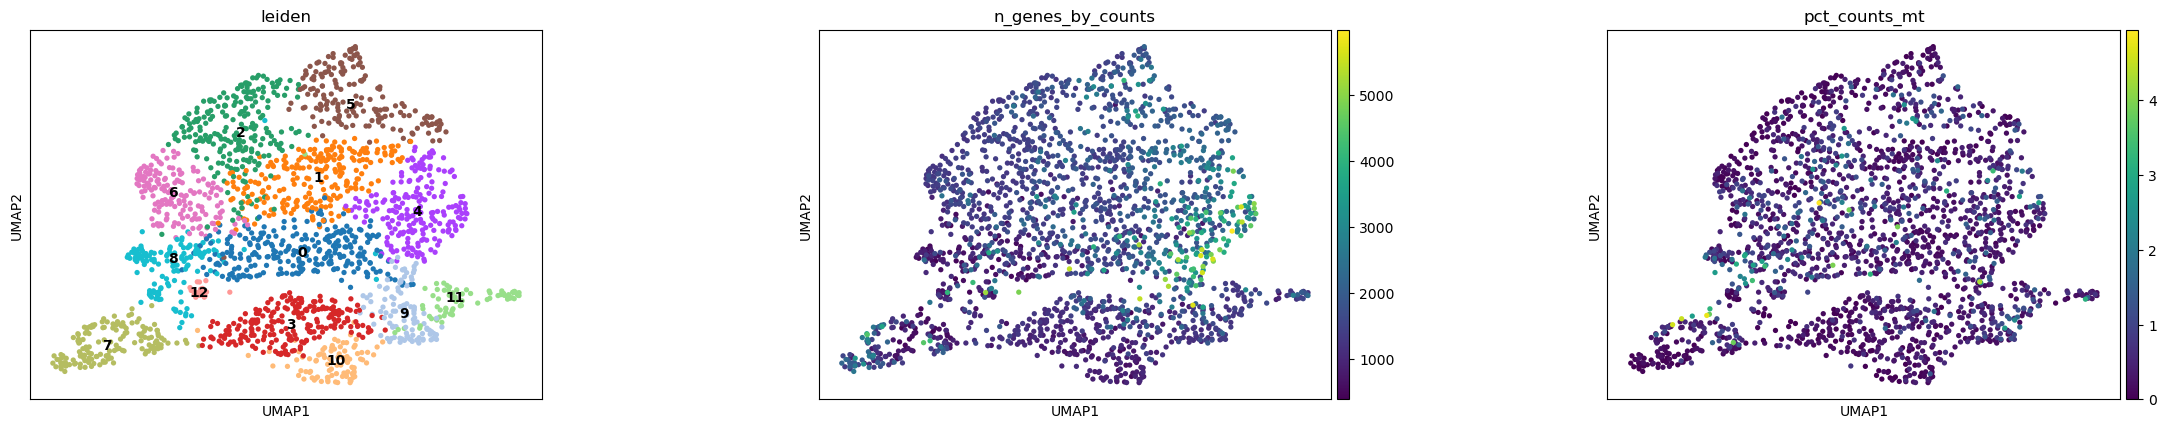

In [18]:
sc.pl.umap(tumor1_data, color=["leiden", "n_genes_by_counts", "pct_counts_mt"], wspace=0.4, legend_loc='on data')

## Cell cycle

In [19]:
s_genes =  ["MCM5",     "PCNA",     "TYMS",     "FEN1",     "MCM2",     "MCM4",    
"RRM1",     "UNG",      "GINS2",    "MCM6",     "CDCA7",    "DTL",     
"PRIM1",    "UHRF1",    "MLF1IP",   "HELLS",    "RFC2",     "RPA2",    
"NASP",     "RAD51AP1", "GMNN",     "WDR76",    "SLBP",     "CCNE2",   
"UBR7",     "POLD3",    "MSH2",     "ATAD2",    "RAD51",    "RRM2",    
"CDC45",    "CDC6",     "EXO1",     "TIPIN",    "DSCC1",    "BLM",
"CASP8AP2", "USP1",     "CLSPN",    "POLA1",    "CHAF1B",   "BRIP1",
"E2F8"]

s_genes = [x for x in s_genes if x in tumor1_data.var_names]


g2m_genes = ["HMGB2",   "CDK1",   "NUSAP1",  "UBE2C",   "BIRC5",   "TPX2",   
"TOP2A",  "NDC80",   "CKS2",    "NUF2",    "CKS1B",   "MKI67",  
"TMPO",    "CENPF",   "TACC3",   "FAM64A",  "SMC4",    "CCNB2",  
"CKAP2L",  "CKAP2",   "AURKB",   "BUB1",    "KIF11",   "ANP32E", 
"TUBB4B",  "GTSE1",   "KIF20B",  "HJURP",   "CDCA3",   "HN1",    
"CDC20",   "TTK",     "CDC25C",  "KIF2C",   "RANGAP1", "NCAPD2", 
"DLGAP5",  "CDCA2",   "CDCA8",   "ECT2",    "KIF23",   "HMMR",
"AURKA",   "PSRC1",   "ANLN",    "LBR" ,    "CKAP5",     "CENPE",
"CTCF",    "NEK2",    "G2E3",    "GAS2L3",  "CBX5",    "CENPA"]

g2m_genes = [x for x in g2m_genes if x in tumor1_data.var_names]

cell_cycle_genes = [*s_genes, *g2m_genes]

In [20]:
sc.tl.score_genes_cell_cycle(tumor1_data, s_genes=s_genes, g2m_genes=g2m_genes)

... storing 'phase' as categorical


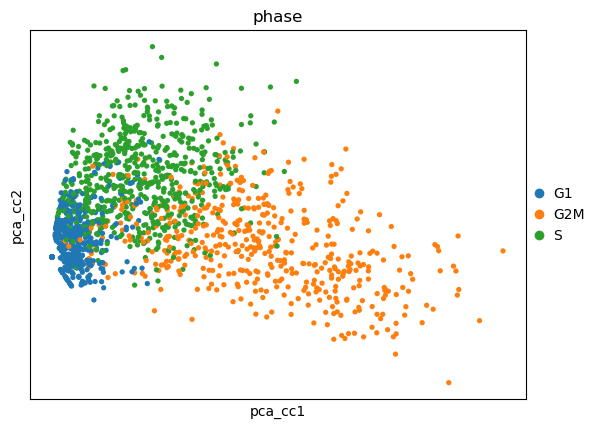

In [21]:
tumor1_datacc_genes = tumor1_data[:, cell_cycle_genes].copy()
sc.tl.pca(tumor1_datacc_genes, layer="scale.data", key_added="pca_cc")
sc.pl.embedding(tumor1_datacc_genes, color="phase", basis="pca_cc")

## Rank genes

In [22]:
sc.tl.rank_genes_groups(tumor1_data, groupby="leiden",  method="wilcoxon", use_raw=False)

... storing 'phase' as categorical


In [23]:
#checking to see if X is log-transformed. It must be normalized too, don't know if that's bad
tumor1_data.X.toarray()

array([[0.       , 1.9184766, 0.       , ..., 0.       , 4.079328 ,
        1.9184766],
       [0.       , 0.       , 0.       , ..., 0.       , 3.4976165,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 1.1552631, ..., 0.       , 2.7864923,
        1.6770437],
       [1.6452588, 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ]], shape=(2069, 18082), dtype=float32)

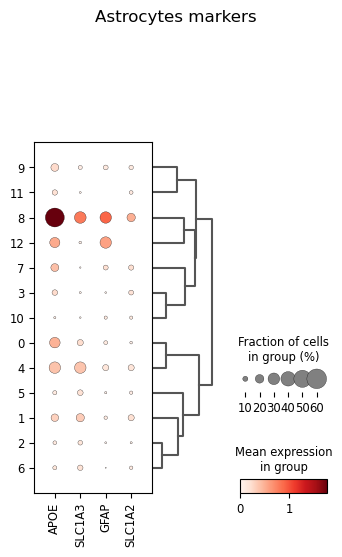

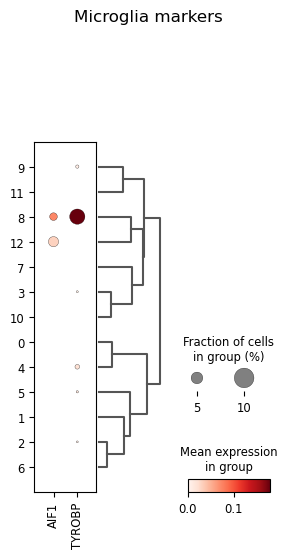

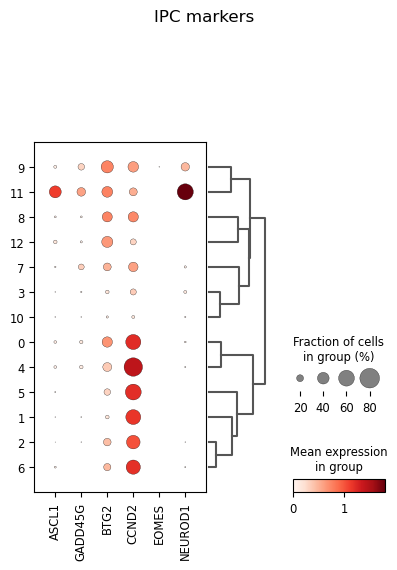

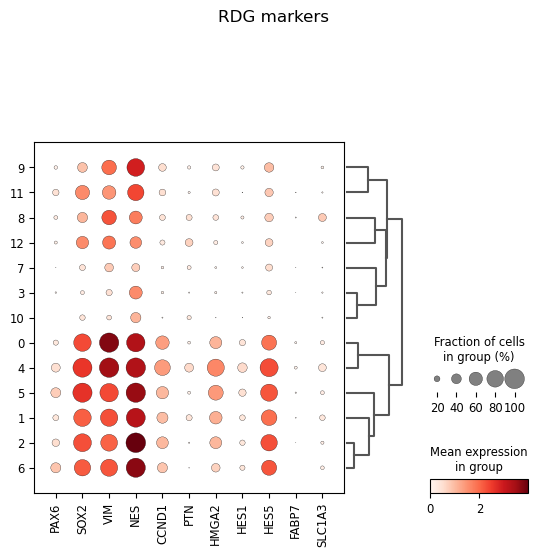

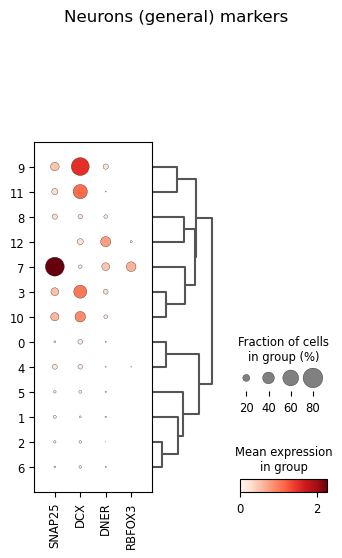

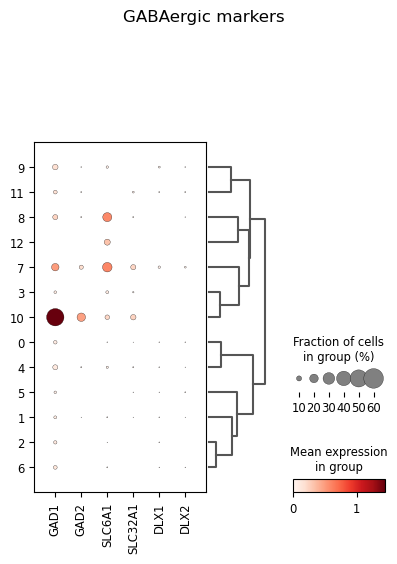

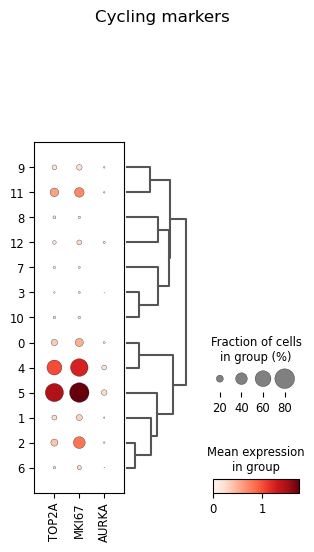

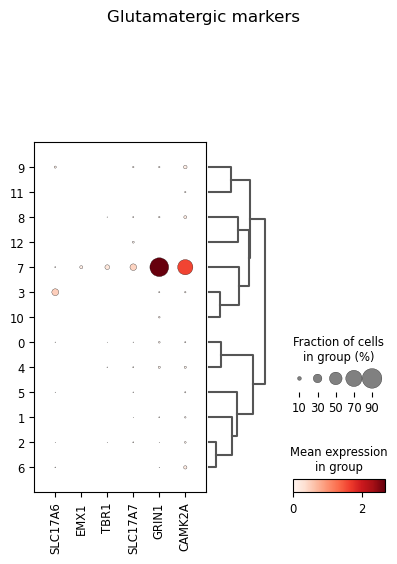

In [24]:
etmr1_markers = {
  "Astrocytes": ["APOE", "SLC1A3", "GFAP", "SLC1A2"], # ASTROCITOS
  "Microglia": ["AIF1", "TYROBP"],  # MICROGLIA
  "IPC": ["ASCL1", "GADD45G", "BTG2", "CCND2", "EOMES", "NEUROD1"], # IPC
  "RDG": ["PAX6", "SOX2", "VIM", "NES", "CCND1", "PTN", "HMGA2", "HES1", "HES5", "FABP7", "SLC1A3"], # RDG
  "Neurons (general)": ["SNAP25", "DCX", "DNER", "RBFOX3"], # NEURONA
  "GABAergic": ["GAD1", "GAD2", "SLC6A1", "SLC32A1", "DLX1", "DLX2"], # GABAÉRGICAS
  "Cycling": ["TOP2A", "MKI67", "AURKA"], # Cycling
  "Glutamatergic": ["SLC17A6", "EMX1", "TBR1", "SLC17A7", "GRIN1", "CAMK2A"] # GLUTAMATÉRGICAS
}

sc.tl.dendrogram(tumor1_data, groupby="leiden")

for name, genes in etmr1_markers.items(): 
    sc.pl.dotplot(tumor1_data, var_names=genes, groupby="leiden", standard_scale=None, show=False, dendrogram=True)
    plt.suptitle(f"{name} markers")
    plt.show()


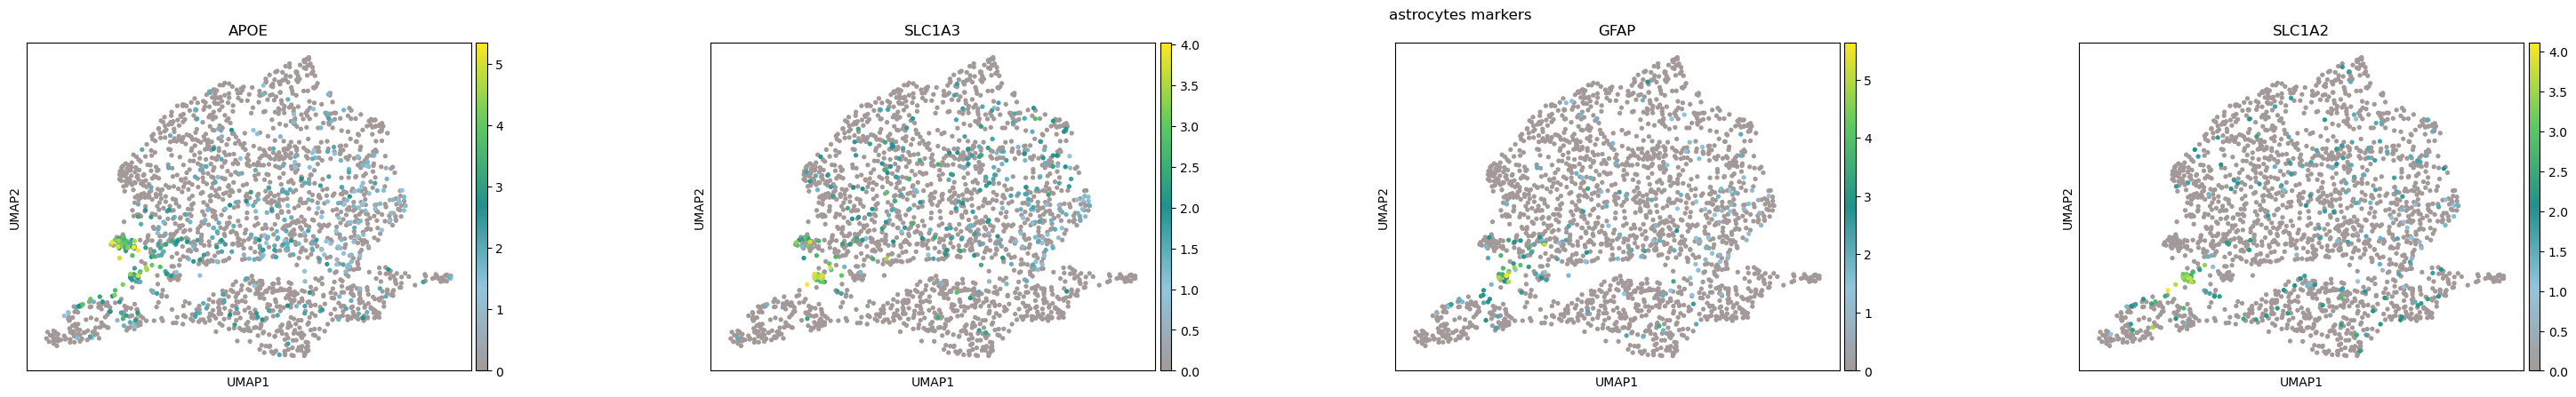

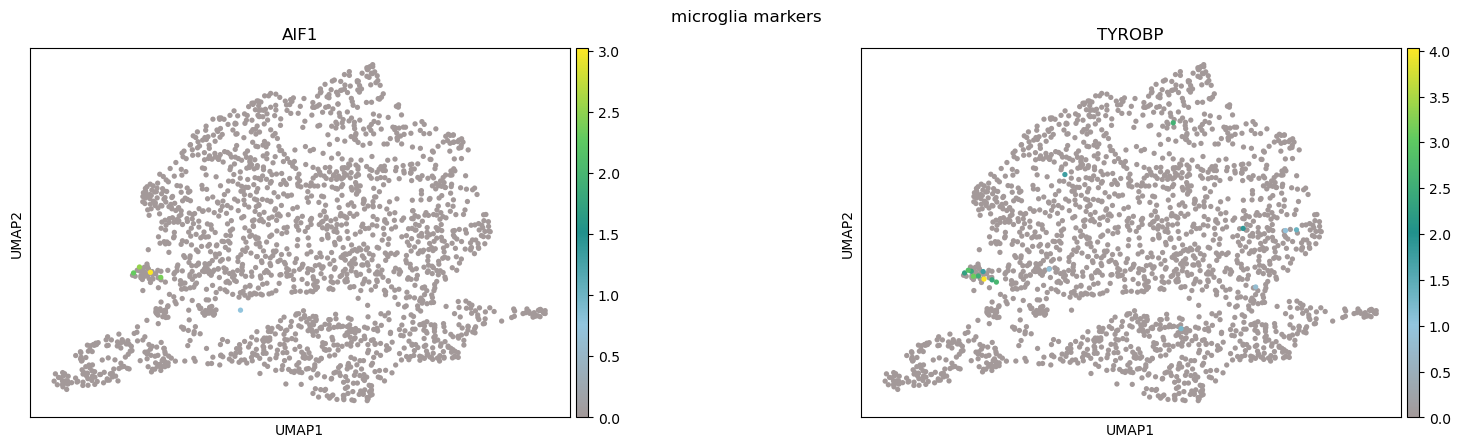

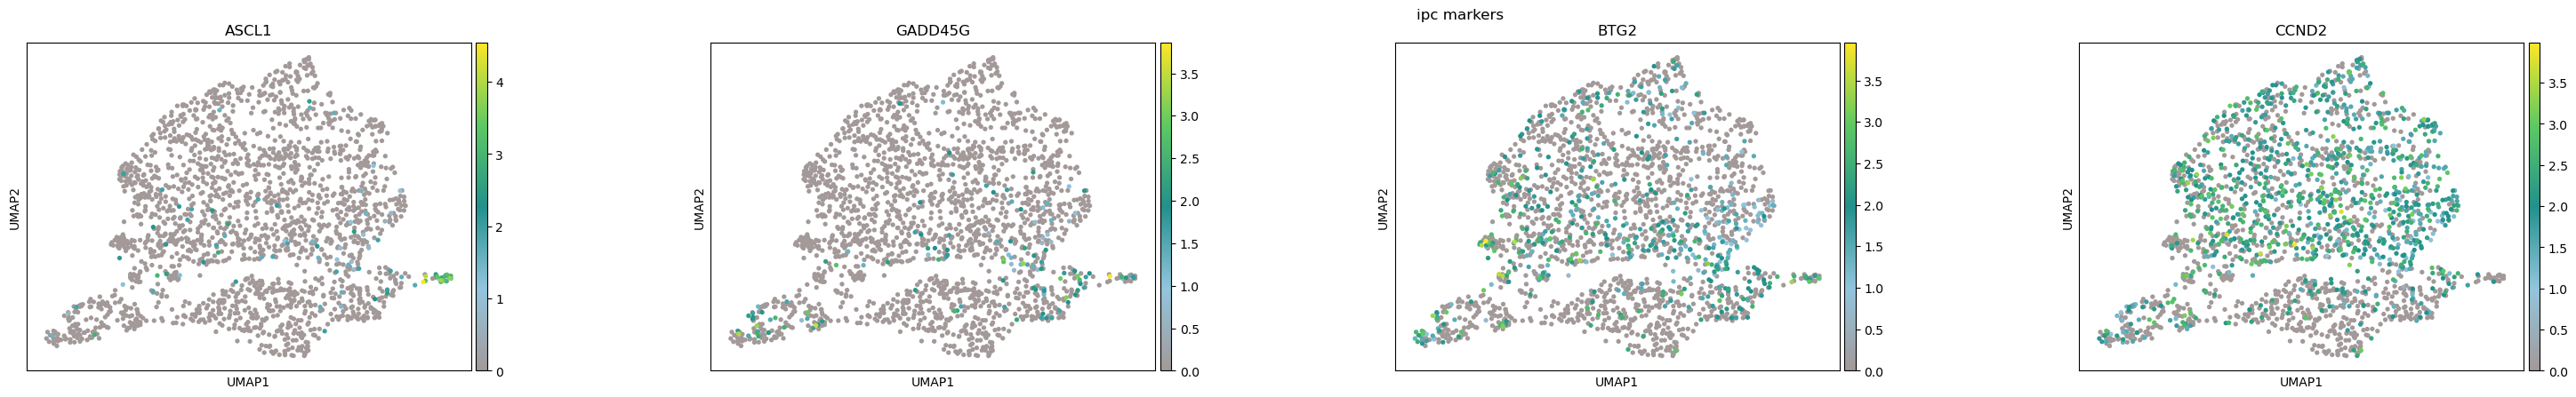

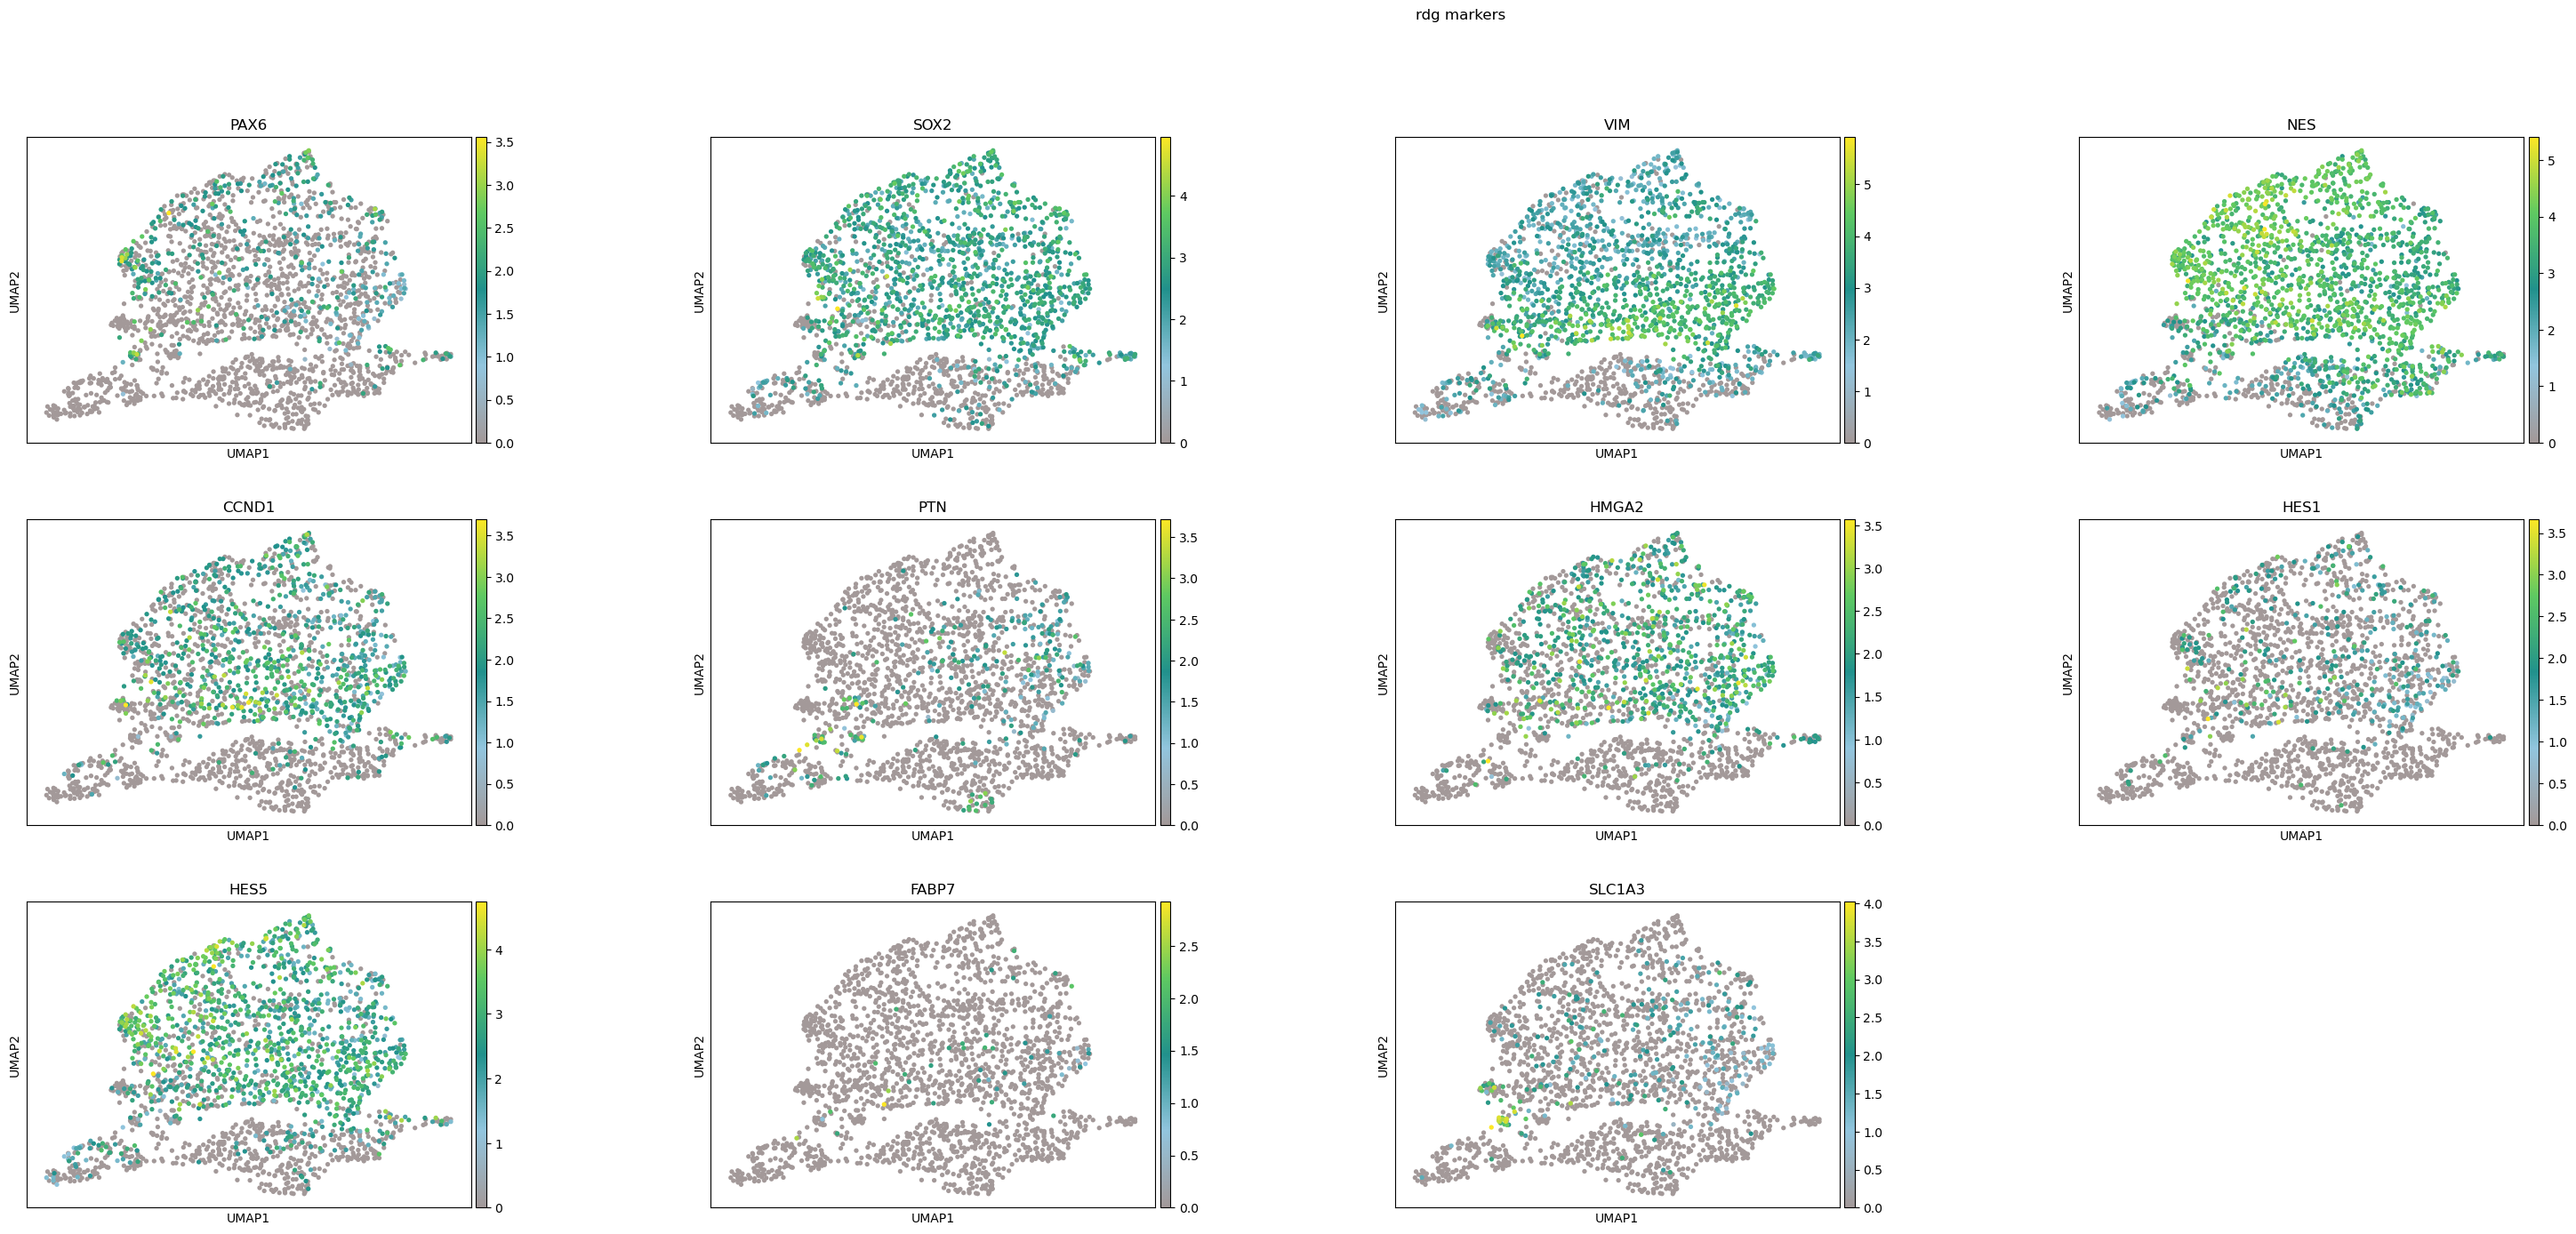

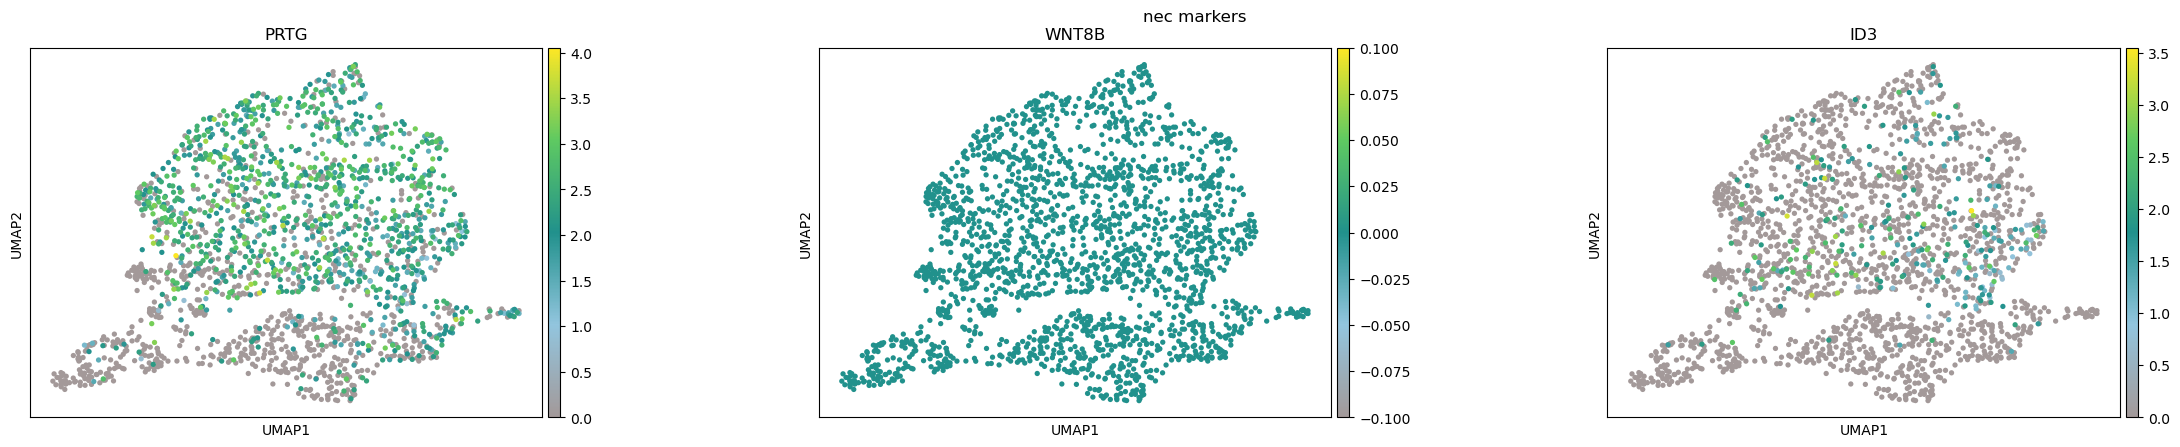

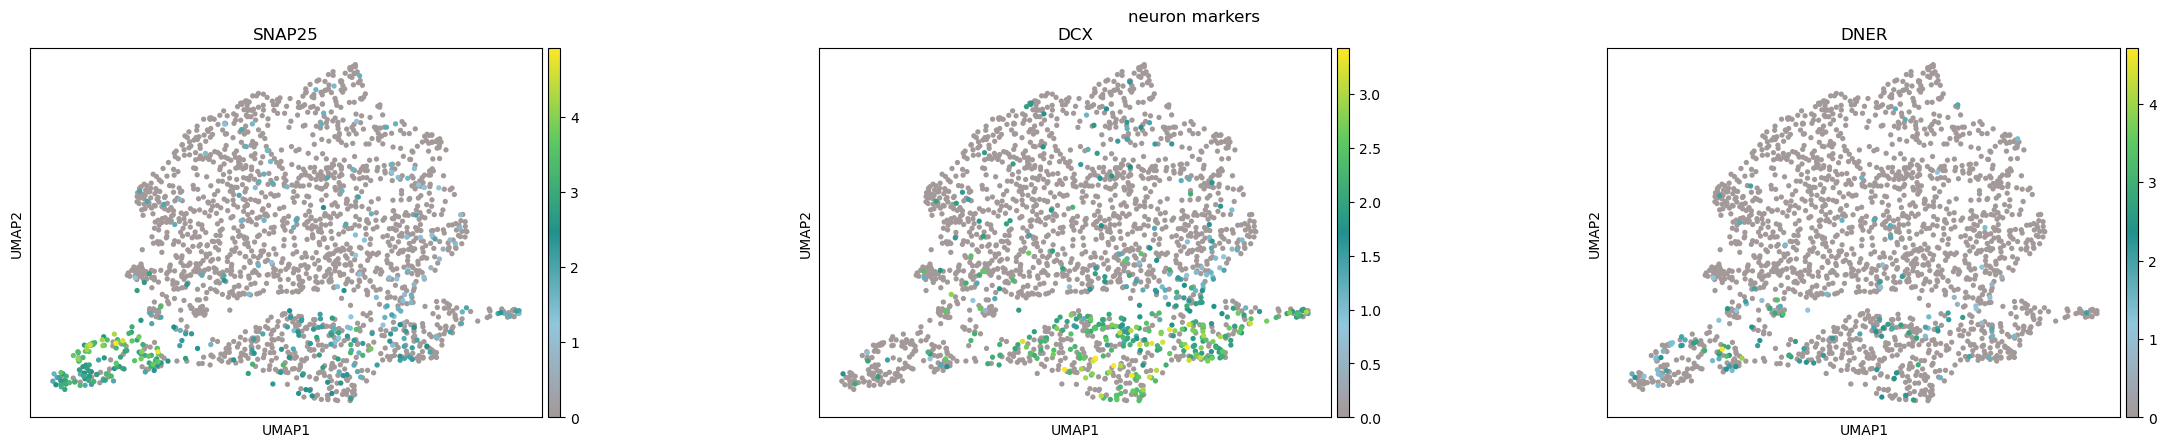

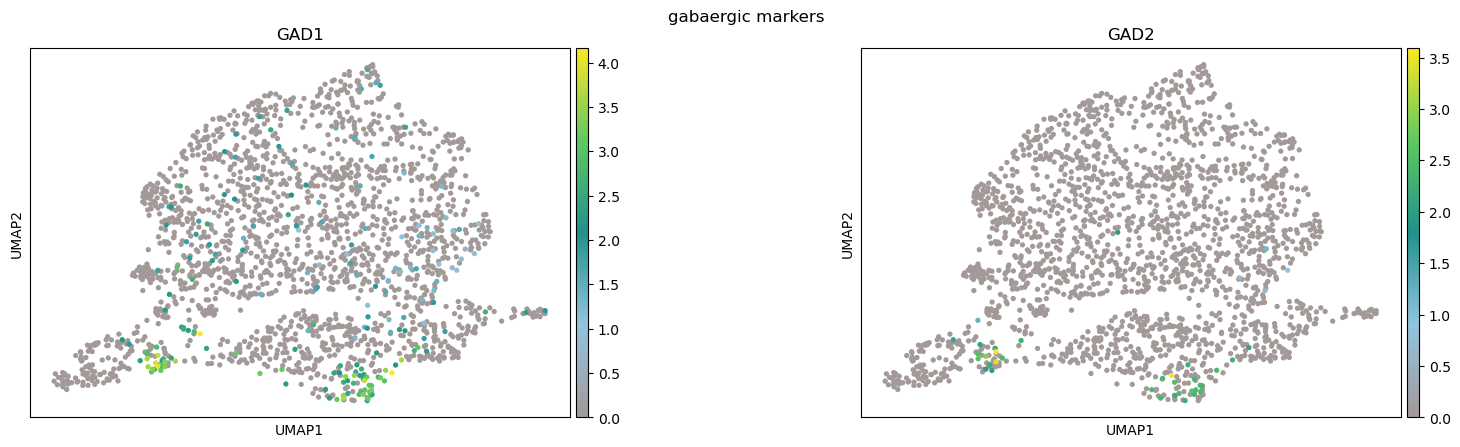

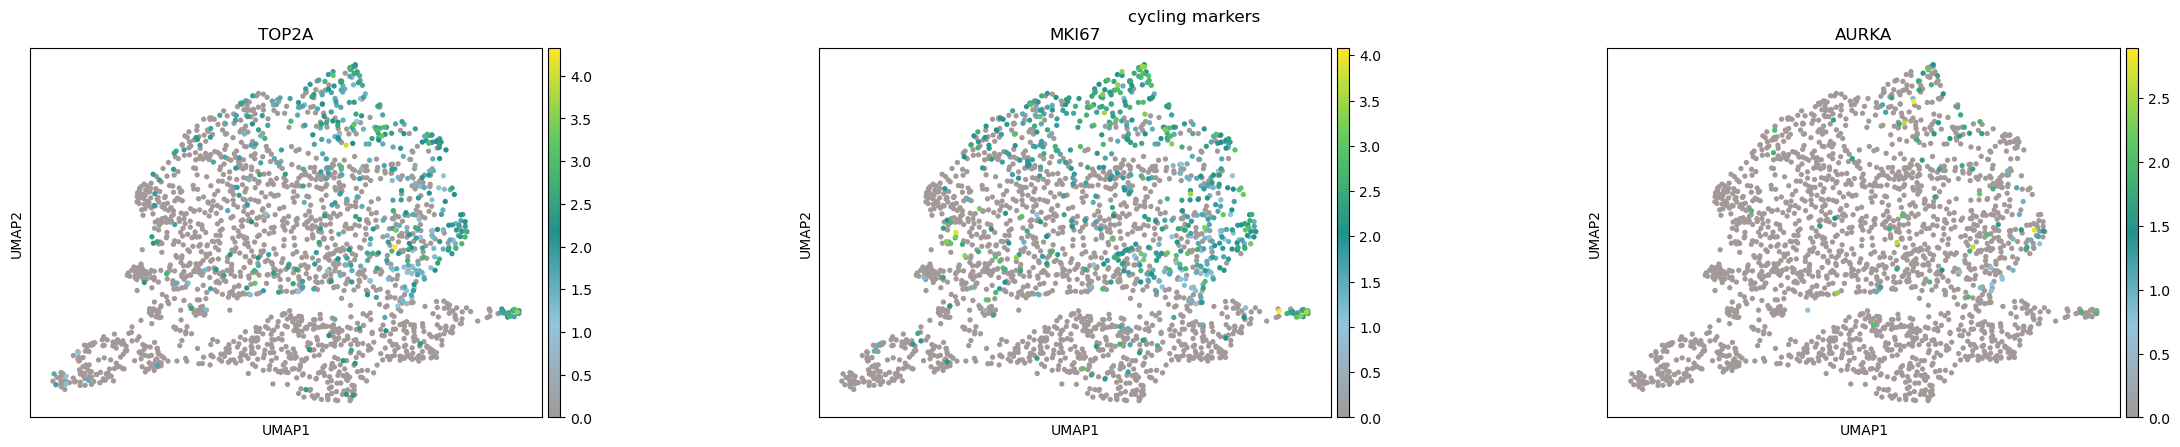

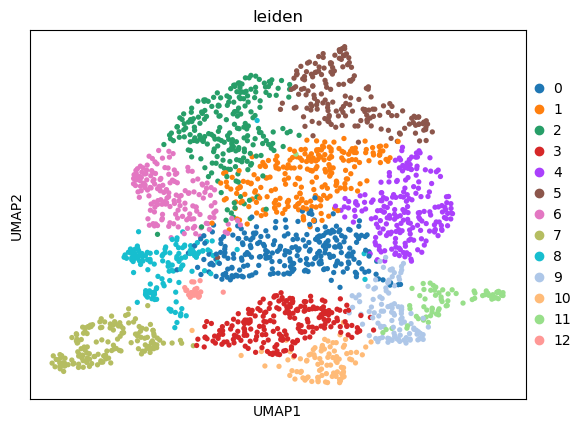

In [25]:
markerslist = {
"astrocytes" : ["APOE", "SLC1A3", "GFAP", "SLC1A2"],
  "microglia" : ["AIF1", "TYROBP"],
  "ipc" : ["ASCL1", "GADD45G", "BTG2", "CCND2"],
  "rdg" : ["PAX6", "SOX2", "VIM", "NES", "CCND1", "PTN", "HMGA2", "HES1", "HES5", "FABP7", "SLC1A3"],
  "nec" : ["PRTG",  "WNT8B", "ID3"],
  "neuron" : ["SNAP25", "DCX", "DNER"],
  "gabaergic" : ["GAD1", "GAD2"],
  "cycling" : ["TOP2A", "MKI67", "AURKA"]
}

custom = LinearSegmentedColormap.from_list(
    "custom",
    ["#a39999", "#92c5de", "#21918c", "#5ec962", "#fde725"]
)

for name, genes in markerslist.items(): 
    sc.pl.embedding(tumor1_data, basis="umap", color=genes, wspace=0.4, show=False, color_map=custom, vmin=0)
    plt.suptitle(f"{name} markers")
    plt.show()

sc.pl.embedding(tumor1_data, basis="umap", color="leiden", wspace=0.4)

In [13]:
tumor1_data.write_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/GSM8058157_KK22-H-225_preprocessed.h5ad")

## Filter and concatenate

In [2]:
tumor1_data = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/GSM8058157_KK22-H-225_preprocessed.h5ad")
tumor1_data

AnnData object with n_obs × n_vars = 2069 × 18082
    obs: 'orig.ident', 'mutation', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'hvg', 'log1p'
    layers: 'counts', 'scale.data'

In [3]:
humanized_data = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/mouse/so_12_SP_WT_KO_joined_humanized.h5ad")
humanized_data.X = humanized_data.layers["counts"]
tumor1_data.X = tumor1_data.layers["counts"]

In [4]:
humanized_data.raw = humanized_data.copy()
tumor1_data.raw = tumor1_data.copy()

In [5]:
tumor1_data.obs

,orig.ident,mutation,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
AAACAAGCATTCGGTTACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,1395,1721.0,15.0,0.871586,0.0,0.0
AAACCAGGTTGCATCGACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,1646,2185.0,11.0,0.503432,0.0,0.0
AAACGGGCAATAACCGACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,924,1090.0,0.0,0.000000,0.0,0.0
AAACTGGGTGCACAAAACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,2196,3515.0,1.0,0.028450,0.0,0.0
AAAGATGCAATCGTGAACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,746,835.0,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...
TTTGGACGTATGGTCTACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,1895,2610.0,4.0,0.153257,0.0,0.0
TTTGGACGTCCAATACACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,1397,1732.0,1.0,0.057737,0.0,0.0
TTTGGCGGTATGTTGCACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,1067,1257.0,1.0,0.079554,0.0,0.0
TTTGTGAGTCATTATGACTACTCA-1-GSM8058157_KK22-H-225,GSM8058157_KK22-H-225,C19MC,3005,4598.0,22.0,0.478469,0.0,0.0


In [ ]:
mask = humanized_data.var_names.intersection(tumor1_data.var_names)
mask
humanized_data_filtered = humanized_data[:, mask].copy()
tumor1_filtered = tumor1_data[:, mask].copy()


In [8]:
joined_human_mouse = humanized_data_filtered.concatenate(tumor1_filtered, batch_key="species", batch_categories=["mouse", "human"], uns_merge="unique")

In [14]:
joined_human_mouse.X

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 197599429 stored elements and shape (45114, 15196)>

In [15]:
joined_human_mouse.layers["counts"]

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 197599429 stored elements and shape (45114, 15196)>

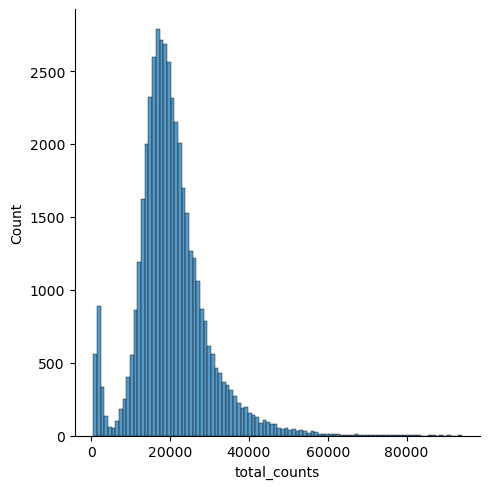

In [11]:

sc.pp.highly_variable_genes(joined_human_mouse, flavor='seurat_v3', layer="counts")
sc.pp.normalize_total(joined_human_mouse, target_sum=1e4) #library size normalization
sc.pp.log1p(joined_human_mouse) #log-transformation
p1 = sns.displot(joined_human_mouse.obs["total_counts"], bins=100, kde=False)

joined_human_mouse.layers["scale.data"] = joined_human_mouse.X.copy()
sc.pp.scale(joined_human_mouse, layer="scale.data")

In [12]:
joined_human_mouse.layers["counts"].toarray()[5:10, 5:10]

array([[0., 3., 0., 0., 1.],
       [0., 5., 0., 1., 1.],
       [0., 5., 0., 0., 2.],
       [0., 1., 0., 3., 1.],
       [0., 3., 0., 0., 2.]])

In [13]:
joined_human_mouse.X.toarray()[5:10, 5:10]

array([[0.        , 1.06535323, 0.        , 0.        , 0.49100322],
       [0.        , 1.59462798, 0.        , 0.57958602, 0.57958602],
       [0.        , 1.46021335, 0.        , 0.        , 0.8427524 ],
       [0.        , 0.79262586, 0.        , 1.53203179, 0.79262586],
       [0.        , 0.81081449, 0.        , 0.        , 0.60604112]])

In [ ]:
joined_human_mouse.write_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/tumor1_so_12_SP_WT_KO_joined.h5ad")

## Integrate

### Harmony

In [6]:
joined_human_mouse = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/tumor1_so_12_SP_WT_KO_int.h5ad")
joined_human_mouse

AnnData object with n_obs × n_vars = 45114 × 15196
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_origin', 'nf', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'S_score', 'G2M_score', 'phase', 'celltype', 'condition', 'orig.ident', 'mutation', 'species'
    var: 'mt', 'ribo', 'highly_variable-human', 'highly_variable_rank-human', 'means-human', 'variances-human', 'variances_norm-human', 'mean-human', 'std-human', 'gene_ids-human', 'feature_types-human', 'n_cells_by_counts-human', 'mean_counts-human', 'pct_dropout_by_counts-human', 'total_counts-human', 'names-mouse', 'n_cells_by_counts-KO-mouse', 'mean_counts-KO-mouse', 'pct_dropout_by_counts-KO-mouse', 'total_counts-KO-mouse', 'highly_variable-KO-mouse', 'highly_variable_rank-KO-mouse', 'means-KO-mouse', 'variances-KO-mouse', 'variances_norm-KO-mouse', 'mean-KO-mouse', 'std-KO-mouse', 'n_cells_by_counts-WT-mouse', 'mean_counts-WT-mouse', 'pct_dropout_by_counts

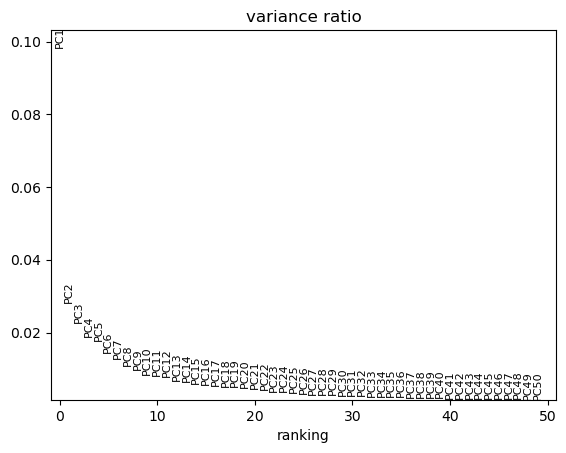

In [7]:
sc.pp.pca(joined_human_mouse, use_highly_variable=True,  n_comps=50, layer="scale.data")
sc.pl.pca_variance_ratio(joined_human_mouse, n_pcs=50, log=False)
sc.pp.neighbors(
                joined_human_mouse,
                n_neighbors=20,
                n_pcs=30
            )

            # UMAP
sc.tl.umap(
                joined_human_mouse
            )

            # Leiden
sc.tl.leiden(
                joined_human_mouse,
                resolution=.8
            )

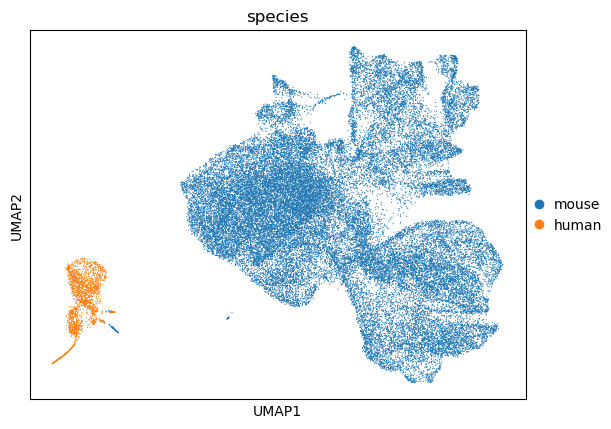

In [8]:
sc.pl.embedding(joined_human_mouse, basis="umap", color="species", wspace=0.4)

In [9]:
sce.pp.harmony_integrate(joined_human_mouse, key="species", max_iter_harmony=20)

2026-02-09 18:40:13,173 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-02-09 18:40:13 | [INFO] Computing initial centroids with sklearn.KMeans...
2026-02-09 18:40:25,292 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-02-09 18:40:25 | [INFO] sklearn.KMeans initialization complete.
2026-02-09 18:40:25,573 - harmonypy - INFO - Iteration 1 of 20
2026-02-09 18:40:25 | [INFO] Iteration 1 of 20
2026-02-09 18:40:44,263 - harmonypy - INFO - Iteration 2 of 20
2026-02-09 18:40:44 | [INFO] Iteration 2 of 20
2026-02-09 18:41:02,829 - harmonypy - INFO - Iteration 3 of 20
2026-02-09 18:41:02 | [INFO] Iteration 3 of 20
2026-02-09 18:41:21,403 - harmonypy - INFO - Converged after 3 iterations
2026-02-09 18:41:21 | [INFO] Converged after 3 iterations


In [10]:
joined_human_mouse

AnnData object with n_obs × n_vars = 45114 × 15196
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_origin', 'nf', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'S_score', 'G2M_score', 'phase', 'celltype', 'condition', 'orig.ident', 'mutation', 'species'
    var: 'mt', 'ribo', 'highly_variable-human', 'highly_variable_rank-human', 'means-human', 'variances-human', 'variances_norm-human', 'mean-human', 'std-human', 'gene_ids-human', 'feature_types-human', 'n_cells_by_counts-human', 'mean_counts-human', 'pct_dropout_by_counts-human', 'total_counts-human', 'names-mouse', 'n_cells_by_counts-KO-mouse', 'mean_counts-KO-mouse', 'pct_dropout_by_counts-KO-mouse', 'total_counts-KO-mouse', 'highly_variable-KO-mouse', 'highly_variable_rank-KO-mouse', 'means-KO-mouse', 'variances-KO-mouse', 'variances_norm-KO-mouse', 'mean-KO-mouse', 'std-KO-mouse', 'n_cells_by_counts-WT-mouse', 'mean_counts-WT-mouse', 'pct_dropout_by_counts

In [12]:
sc.pp.neighbors(
                joined_human_mouse,
                n_neighbors=20,
                n_pcs=30,
                use_rep="X_pca_harmony"
            )

            # UMAP
sc.tl.umap(
                joined_human_mouse
            )

            # Leiden
sc.tl.leiden(
                joined_human_mouse,
                resolution=.8
            )

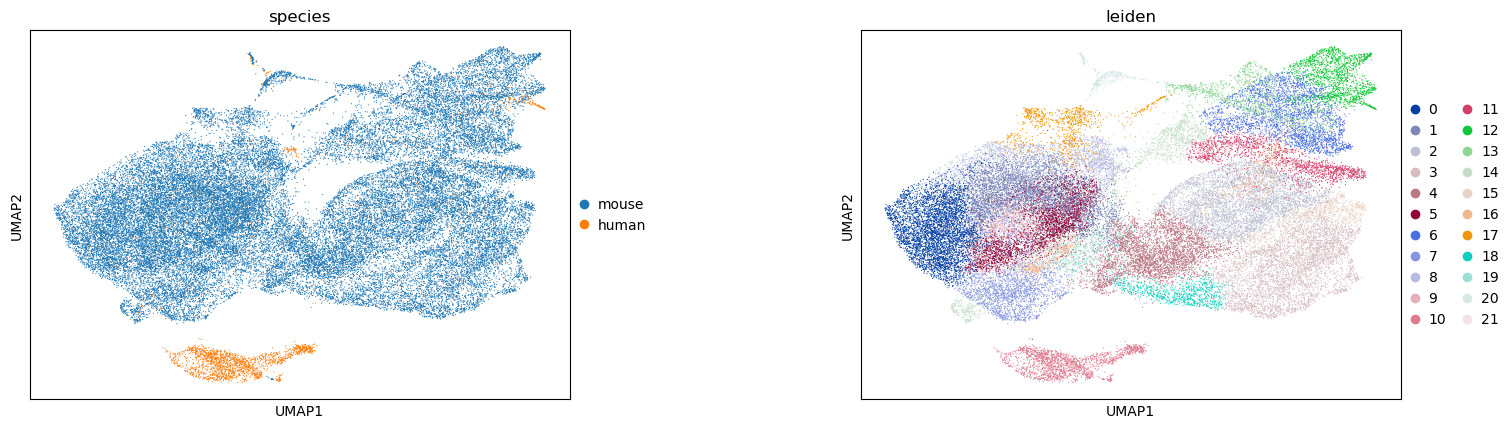

In [15]:
sc.pl.embedding(joined_human_mouse, basis="umap", color=["species", "leiden"], wspace=0.4)

In [16]:
joined_human_mouse.write_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/tumor1_so_12_SP_WT_KO_int.h5ad")

## Checkpoint 2

In [2]:
joined_human_mouse = sc.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/tumor1_so_12_SP_WT_KO_int.h5ad")

In [2]:
joined_human_mouse

#This needs cleaning

NameError: name 'joined_human_mouse' is not defined

In [11]:
joined_human_mouse.obs.groupby(["leiden", "species"]).size().to_excel("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/harmony/tumor1_so_12_SP_WT_KO_int_leiden_species_counts.xlsx")

In [8]:
124/1530*100

8.104575163398692